In [11]:
import sys
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print('Python:    ', sys.version.split()[0])
print('pandas:    ', version('pandas'))
print('matplotlib:', version('matplotlib'))
print('seaborn:   ', version('seaborn'))

sns.set_theme(style='darkgrid')

listings = pd.read_csv('data/listings_clean.csv', parse_dates=['first_review', 'last_review'])

print(listings.shape)


Python:     3.14.10
pandas:     3.0.5
matplotlib: 3.11.2
seaborn:    0.13.2
(4574, 73)


In [12]:
listings['price'].describe()


count     2957.000000
mean      2327.643382
std       2160.353619
min        120.000000
25%       1071.120000
50%       1791.000000
75%       3003.800000
max      40000.000000
Name: price, dtype: float64

## Claim 1: “A night in Stockholm costs 1,791.”

Holds with many reservations. The claim is unclear. 1,791 what? A night – at the bar? At Grand Hotel? 

The prices of a Air BnB listing in Stockholm september 2026 has a price range between 120 and 40000 kr and IQR is between 1071 and 3003 kr. The median is 1971 kr. This is for 2957 listings with a price. The median is 1791 kr per night. Mean is 2328 kr. 

## Claim 2: “The listings with a perfect 5.00 rating are the best in Stockholm.”

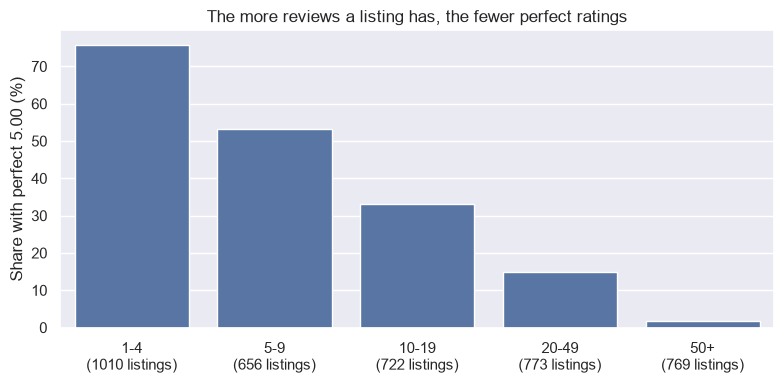

In [14]:
rated = listings[listings['review_scores_rating'].notna()]
perfect = rated['review_scores_rating'] == 5.0
review_group = pd.cut(rated['number_of_reviews'],
                      bins=[0, 4, 9, 19, 49, np.inf],
                      labels=['1-4', '5-9', '10-19', '20-49', '50+'])

result = perfect.groupby(review_group).agg(['count', 'mean']).reset_index()

result['percent'] = result['mean'] * 100
result['label'] = result['number_of_reviews'].astype(str) + '\n(' + result['count'].astype(str) + ' listings)'

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(data=result, x='label', y='percent', ax=ax)

ax.set_title('The more reviews a listing has, the fewer perfect ratings')
ax.set_xlabel('')
ax.set_ylabel('Share with perfect 5.00 (%)')

plt.tight_layout()
plt.show()

In [15]:
print(result[['number_of_reviews', 'count', 'percent']])

  number_of_reviews  count    percent
0               1-4   1010  75.841584
1               5-9    656  53.201220
2             10-19    722  33.102493
3             20-49    773  15.006468
4               50+    769   1.820546


Verdict: Claim does not hold. Mainly listings with only a few reviews have top scores.

Of the 1,010 listings with 1-4 reviews, 76 percent have a perfect 5. Of the 769 listings with 50 or more reviews, only 2% do. A perfect rating means only a few reviews, not necessary a better listing.

## Claim 3: “The market has grown: only 131 listings started in 2016, but 610 in 2024.”

In [17]:
year = listings['first_review'].dt.year
print(year.value_counts().sort_index())

reviewed_2026 = listings['last_review'].dt.year == 2026
print(reviewed_2026.groupby(year).mean().round(2))

first_review
2011.0      2
2012.0     12
2013.0     26
2014.0     51
2015.0    116
2016.0    131
2017.0    148
2018.0    191
2019.0    234
2020.0     96
2021.0    159
2022.0    332
2023.0    565
2024.0    610
2025.0    542
2026.0    715
Name: count, dtype: int64
first_review
2011.0    1.00
2012.0    0.58
2013.0    0.58
2014.0    0.65
2015.0    0.53
2016.0    0.53
2017.0    0.53
2018.0    0.51
2019.0    0.55
2020.0    0.54
2021.0    0.58
2022.0    0.52
2023.0    0.59
2024.0    0.67
2025.0    0.80
2026.0    1.00
Name: last_review, dtype: float64


Verdict: Cannot be concluded from this data

The data is a snapshot from september 2026. Listings from earlier years might have been deleted. Of older listing roughly 50-60 % have a review from 2026. Same for all years 2012-2023.
Of the listings that still exist, 131 got their first review in 2016 and 610 in 2024. We can not say how many were started in those years.

## Claim 4: “Most hosts in Stockholm are professional companies with many listings.”

In [19]:
print('listings:', len(listings), 'hosts:', listings['host_id'].nunique())

per_host = listings.groupby('host_id').size()

print(per_host.value_counts().sort_index().head())
print('largest host:', per_host.max())

listings: 4574 hosts: 3591
1    3237
2     207
3      65
4      21
5      11
Name: count, dtype: int64
largest host: 49


Most hosts have only on listning. Only a few hosts have more than 2 listnings. The data does not say if it's companies or not. Is 147 hosts with more than 2 listings "a lot"? Probaly not.

Claim does not hold.

## Task 5: A data note


In [22]:
n = len(listings)
print('listings:', n, 'hosts:', listings['host_id'].nunique())

no_price = listings['price'].isna()
print('missing price:', no_price.sum(), (no_price.mean() * 100).round(1), 'percent')

no_rating = listings['review_scores_rating'].isna()
print('missing rating:', no_rating.sum(), (no_rating.mean() * 100).round(1), 'percent')

no_reviews = listings['number_of_reviews'] == 0
print('no reviews:', no_reviews.sum(), (no_reviews.mean() * 100).round(1), 'percent')

print('missing rating and no reviews:', (no_rating & no_reviews).sum())

no_days = listings['availability_365'] == 0
print('missing price and no open days:', (no_price & no_days).sum())

print((listings.isna().mean() * 100).round(1).sort_values(ascending=False).head(10))

print([c for c in listings.columns if c.startswith('estimated_')])

listings: 4574 hosts: 3591
missing price: 1617 35.4 percent
missing rating: 644 14.1 percent
no reviews: 644 14.1 percent
missing rating and no reviews: 644
missing price and no open days: 1490
source                         62.7
price                          35.4
price_quote_total_price        35.4
price_quote_price_per_night    35.4
estimated_revenue_l365d        35.4
price_quote_checkout_date      34.0
price_quote_raw                34.0
price_quote_checkin_date       34.0
review_scores_accuracy         14.1
last_review                    14.1
dtype: float64
['estimated_occupancy_l365d', 'estimated_revenue_l365d']


The data comes from Inside Airbnb, who have scaped it from Airbnb –  as far as I understand against their user agreement. Inside Airbnb is a site critical against Airbnb and collects data to show how short-term rentals affect housing and communities around the world.

Inside Airbnb has licenced the data with CC BY 4.0, so anyone using the data must credit insideairbnb.com. The data is an snapshot of Airbnb listnings in Stockholm 26 and 27 September 2026. Discontinued listings for earlier dates are not in the data. New listings from a later date aren't either niether are listings from other platforms och hotel chains.

Some data is missing, 1617 (35%) is missing a price, 644 (14%) is missing a rating and reviews. A lage part of the sites missing price has also not open days (1490 listings). The columns estimated_occupancy_l365d and estimated_revenue_l365d are calculated, not measured and the revenue is missing for the same 35% as the price. 

The table can not tell us why a price is what it is, why a guest was satisfied, or if the market has grown over time. The claims I would most want to correct is no 2, because a perfect 5 rating mostly means few reviews, so it says almost nothing about which host is best.
